# Rainfall Forecasting: Random Forest vs SVR
Research question: Can we predict monthly rainfall given forecasted minimum and maximum temperatures?

This notebook trains and compares two regression models, Random Forest and Support Vector Regression (SVR), on data from three Welsh weather stations (Cardiff, Aberporth, Valley).

# Setup


In [1]:
import time
import sklearn as sk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
from google.colab import files
uploaded = files.upload()

columns = ["Year", "Month", "Min Temp", "Max Temp", "Frost Days", "Rainfall"]
station_names = ["cardiff", "aberporth", "valley"]

stations = {
    name: pd.DataFrame(np.load(f"{name}.npy"), columns=columns)
    for name in station_names
}

for name, df in stations.items():
    print(f"{name}: shape = {df.shape}")

Saving valley.npy to valley.npy
Saving cardiff.npy to cardiff.npy
Saving aberporth.npy to aberporth.npy
cardiff: shape = (556, 6)
aberporth: shape = (811, 6)
valley: shape = (1123, 6)


In [3]:
for name, df in stations.items():
    print(f"===== {name} =====")
    display(df.head())
    print("Missing values:", int(df.isnull().sum().sum()))

===== cardiff =====


,Year,Month,Min Temp,Max Temp,Frost Days,Rainfall
0,1977.0,9.0,18.3,8.1,0.0,48.6
1,1977.0,10.0,15.4,9.0,0.0,76.0
2,1977.0,11.0,10.3,4.7,4.0,147.9
3,1977.0,12.0,9.6,4.6,2.0,88.0
4,1978.0,1.0,7.5,2.0,6.0,134.1


Missing values: 0
===== aberporth =====


,Year,Month,Min Temp,Max Temp,Frost Days,Rainfall
0,1957.0,1.0,8.6,3.9,2.0,80.6
1,1957.0,2.0,8.5,3.2,2.0,85.1
2,1957.0,3.0,12.2,7.4,0.0,83.1
3,1957.0,4.0,11.3,6.2,0.0,7.4
4,1957.0,5.0,13.6,7.4,0.0,54.1


Missing values: 0
===== valley =====


,Year,Month,Min Temp,Max Temp,Frost Days,Rainfall
0,1930.0,12.0,8.6,5.5,0.0,130.3
1,1931.0,1.0,8.0,4.2,0.0,66.2
2,1931.0,2.0,7.6,3.7,0.0,60.6
3,1931.0,3.0,8.5,2.4,6.0,32.5
4,1931.0,4.0,9.9,5.6,0.0,47.1


Missing values: 0


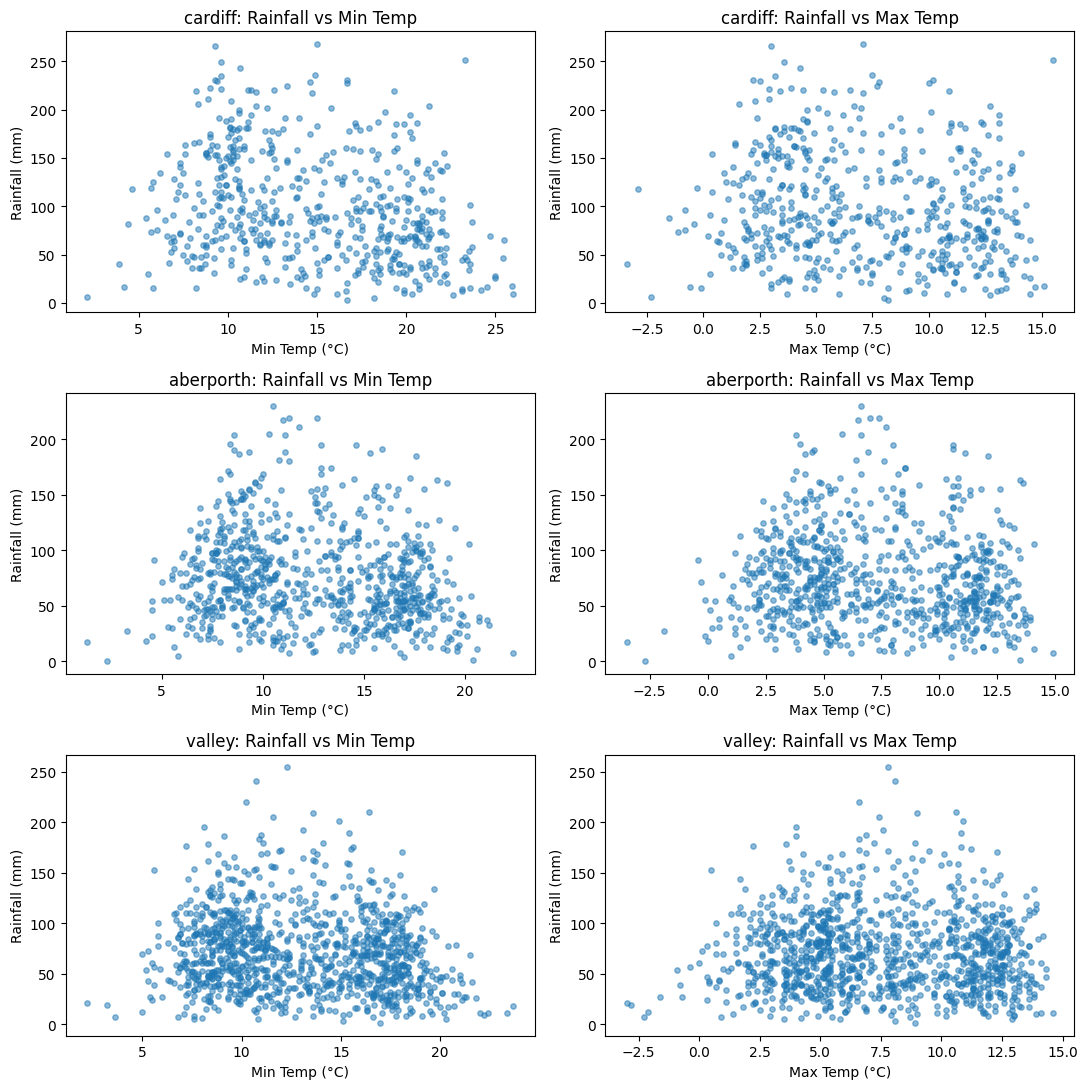

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(11, 11))
for row, (name, df) in enumerate(stations.items()):
    for col, feat in enumerate(["Min Temp", "Max Temp"]):
        axes[row, col].scatter(df[feat], df["Rainfall"], alpha=0.5, s=15)
        axes[row, col].set_xlabel(f"{feat} (°C)")
        axes[row, col].set_ylabel("Rainfall (mm)")
        axes[row, col].set_title(f"{name}: Rainfall vs {feat}")
plt.tight_layout()
plt.show()

In [5]:
features = ["Min Temp", "Max Temp"]
target = "Rainfall"

# Train/Test Split


In [7]:
splits = {}

for name, df in stations.items():
    X = df[features].values
    y = df[target].values

    splits[name] = train_test_split(X, y, test_size=0.2, random_state=42)

    X_tr, X_te, y_tr, y_te = splits[name]
    print(f"{name}: train = {len(X_tr)}, test = {len(X_te)}")

cardiff: train = 444, test = 112
aberporth: train = 648, test = 163
valley: train = 898, test = 225


In [12]:
def evaluate(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

def tune_and_evaluate(estimator, param_grid, splits):
    results, predictions, models = {}, {}, {}

    for name, (X_tr, X_te, y_tr, y_te) in splits.items():
      start = time.time()

      gs = GridSearchCV(estimator, param_grid, cv=5,
                        scoring="neg_root_mean_squared_error", n_jobs=-1,)

      gs.fit(X_tr, y_tr)

      tune_time = time.time() - start
      y_pred = gs.best_estimator_.predict(X_te)
      cv_rmse = -gs.cv_results_["mean_test_score"]

      results[name] = {
          **evaluate(y_te, y_pred),
          "Tuning time (s)": tune_time,
          "CV RMSE spread": max(cv_rmse) - min(cv_rmse),
          "Best params": gs.best_params_,
        }

      predictions[name] = y_pred
      models[name] = gs.best_estimator_

    return results, predictions, models

def plot_pred_vs_actual(predictions, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    for ax, (name, y_pred) in zip(axes, predictions.items()):
        y_te = splits[name][3]

        ax.scatter(y_te, y_pred, alpha=0.6, s=18)

        lims = [min(y_te.min(), y_pred.min()),
                max(y_te.max(), y_pred.max())]

        ax.plot(lims, lims, "r--", label="Perfect prediction")
        ax.set(xlabel="Actual rainfall (mm)",
               ylabel="Predicted rainfall (mm)",
               title=f"{title}: {name}")
        ax.legend()

    plt.tight_layout()
    plt.show()

# Random Forest


In [13]:
rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3, 5],
}

rf_results, rf_preds, rf_models = tune_and_evaluate(
    RandomForestRegressor(random_state=42), rf_param_grid, splits
)

for name, res in rf_results.items():
    print(f"{name}: best params = {res['Best params']}")

cardiff: best params = {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}
aberporth: best params = {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
valley: best params = {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}


# Results

In [14]:
rf_table = pd.DataFrame(rf_results).T.drop(columns=["Best params"])
display(rf_table.astype(float).round(3))

,RMSE,MAE,R2,Tuning time (s),CV RMSE spread
cardiff,46.636,37.835,0.286,29.146,5.185
aberporth,36.736,29.482,0.178,33.687,3.360
valley,35.125,27.970,0.095,34.894,4.517


,Min Temp,Max Temp
cardiff,0.573,0.427
aberporth,0.516,0.484
valley,0.563,0.437


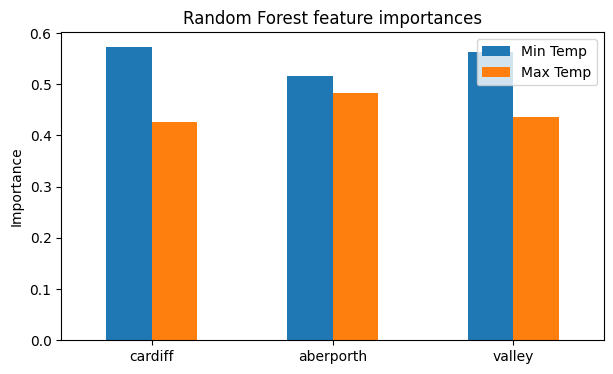

In [15]:
importances = pd.DataFrame(
    {name: model.feature_importances_ for name, model in rf_models.items()},
    index=features,
).T

display(importances.round(3))
importances.plot(kind="bar", figsize=(7, 4), title="Random Forest feature importances")
plt.ylabel("Importance")
plt.xticks(rotation=0)
plt.show()

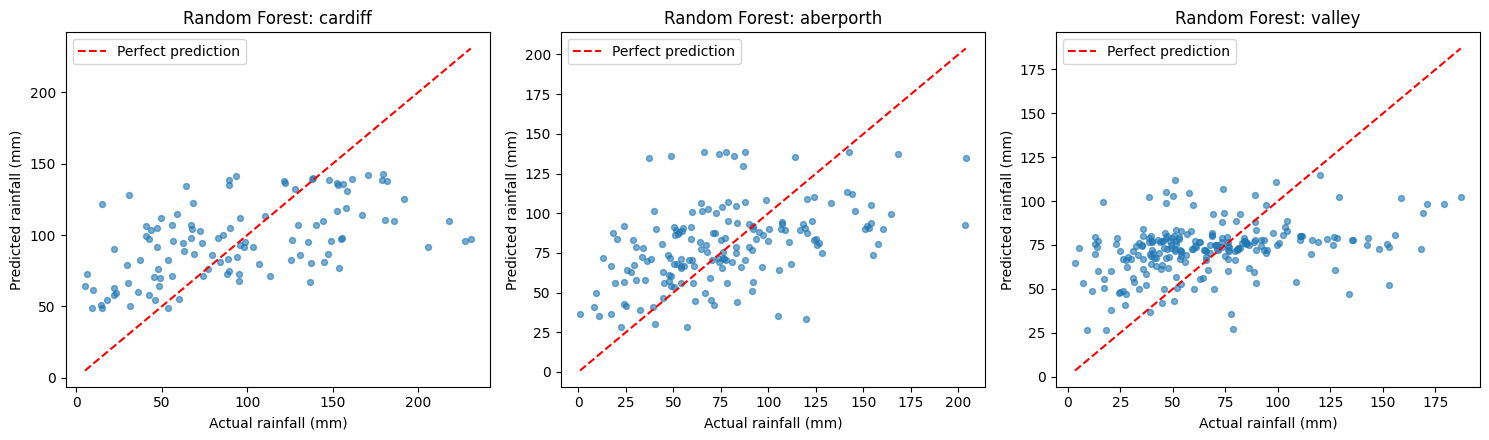

In [16]:
plot_pred_vs_actual(rf_preds, "Random Forest")

# SVR

In [17]:
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf")),
])

svr_param_grid = {
    "svr__C": [1, 10, 100, 1000],
    "svr__epsilon": [0.1, 1, 5, 10],
    "svr__gamma": ["scale", 0.01, 0.1, 1],
}

svr_results, svr_preds, svr_models = tune_and_evaluate(svr_pipeline, svr_param_grid, splits)

for name, res in svr_results.items():
    print(f"{name}: best params = {res['Best params']}")


cardiff: best params = {'svr__C': 100, 'svr__epsilon': 10, 'svr__gamma': 'scale'}
aberporth: best params = {'svr__C': 1000, 'svr__epsilon': 10, 'svr__gamma': 'scale'}
valley: best params = {'svr__C': 1000, 'svr__epsilon': 10, 'svr__gamma': 'scale'}


# Results

In [18]:
svr_table = pd.DataFrame(svr_results).T.drop(columns=["Best params"])
display(svr_table.astype(float).round(3))

,RMSE,MAE,R2,Tuning time (s),CV RMSE spread
cardiff,44.651,35.464,0.345,4.314,8.405
aberporth,36.064,27.815,0.208,9.057,5.972
valley,33.073,26.099,0.198,15.360,5.333


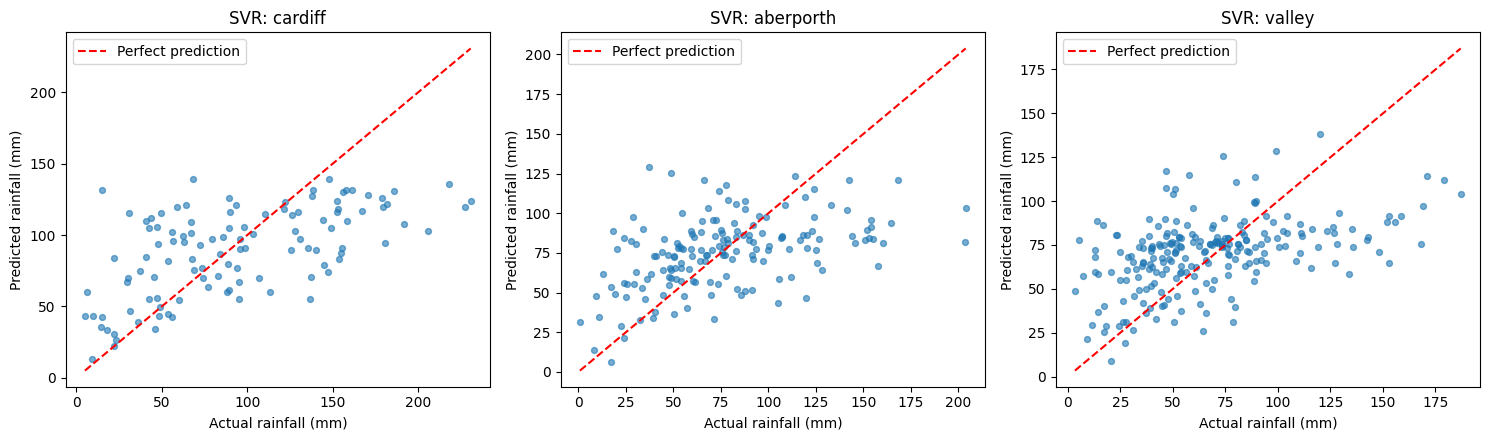

In [19]:
plot_pred_vs_actual(svr_preds, "SVR")

# Evaluation

In [20]:
rf_t = rf_table.copy();   rf_t["Model"] = "Random Forest"
svr_t = svr_table.copy(); svr_t["Model"] = "SVR"

comparison = (
    pd.concat([rf_t, svr_t])
    .reset_index()
    .rename(columns={"index": "Station"})
    .set_index(["Station", "Model"])
    .sort_index()
    .astype(float)
)
display(comparison.round(3))

RMSE     MAE     R2  Tuning time (s)  \
Station   Model                                                   
aberporth Random Forest  36.736  29.482  0.178           33.687   
          SVR            36.064  27.815  0.208            9.057   
cardiff   Random Forest  46.636  37.835  0.286           29.146   
          SVR            44.651  35.464  0.345            4.314   
valley    Random Forest  35.125  27.970  0.095           34.894   
          SVR            33.073  26.099  0.198           15.360   

                         CV RMSE spread  
Station   Model                          
aberporth Random Forest           3.360  
          SVR                     5.972  
cardiff   Random Forest           5.185  
          SVR                     8.405  
valley    Random Forest           4.517  
          SVR                     5.333

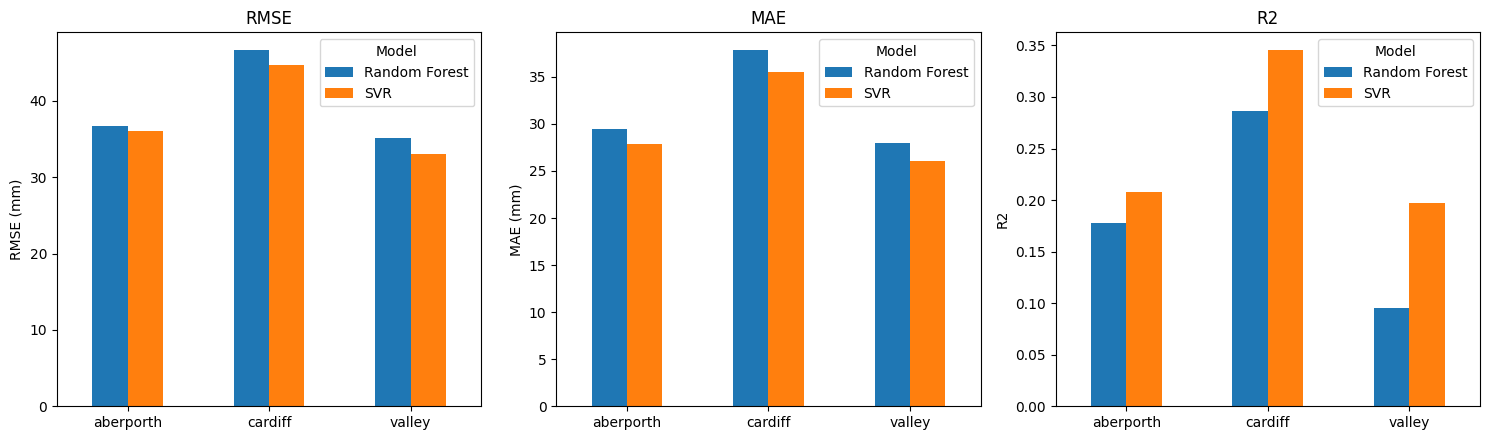

In [21]:
metrics = ["RMSE", "MAE", "R2"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, metrics):
    comparison[metric].unstack("Model").plot(kind="bar", ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel(metric + (" (mm)" if metric != "R2" else ""))
plt.tight_layout()
plt.show()

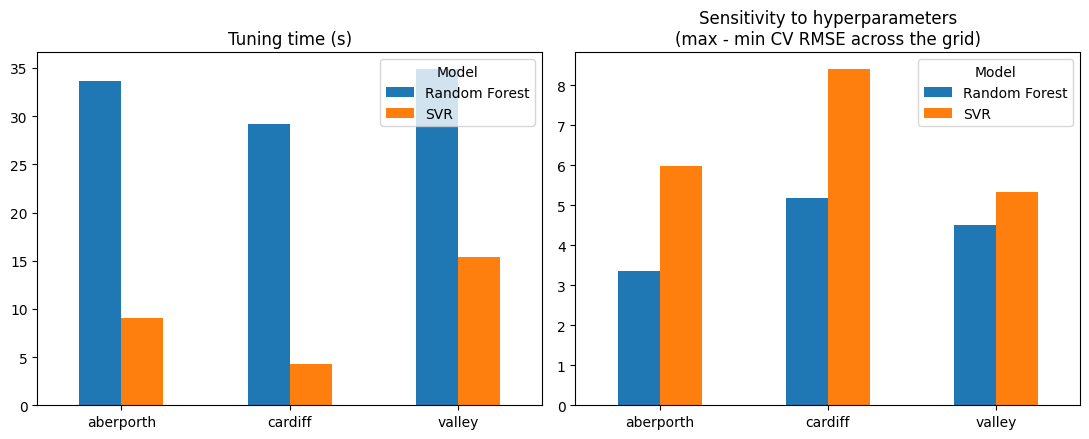

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
comparison["Tuning time (s)"].unstack("Model").plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Tuning time (s)")
comparison["CV RMSE spread"].unstack("Model").plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Sensitivity to hyperparameters\n(max - min CV RMSE across the grid)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()